## **Hexaboard Visual Inspection - Alignment Confirmation**

In [1]:
# --- Default libraries ---
import os
import re
from pathlib import Path

# --- Working directory ---
PROJECT_DIR = Path().resolve()
PROJECT_ROOT_NAME = 'visual-inspection'

while PROJECT_DIR.name != PROJECT_ROOT_NAME and PROJECT_DIR != PROJECT_DIR.parent:
    PROJECT_DIR = PROJECT_DIR.parent

if Path().resolve() != PROJECT_DIR:
    os.chdir(PROJECT_DIR)

DATA_DIR = PROJECT_DIR / 'data'
TRAIN_DIR = DATA_DIR / 'train'
VAL_DIR = DATA_DIR / 'val'
TEST_DIR = DATA_DIR / 'test'
BAD_DIR = DATA_DIR / 'bad'
BOARD_DIRS = {
    'bad': BAD_DIR,
    'train': TRAIN_DIR,
    'val': VAL_DIR,
    'test': TEST_DIR,
}
CALIBRATION_DIR = PROJECT_DIR / 'calibrations'
BOARD_ID_RE = re.compile(r'(320XLF4CQH\d{5})')

# --- Data preprocessing & visualization ---
import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from IPython.display import display

# --- Custom modules ---
from src.utils.data import load_hexaboard

In [ ]:
unaligned_images = np.load('data/bad/320XLF4CQH00008.npy')

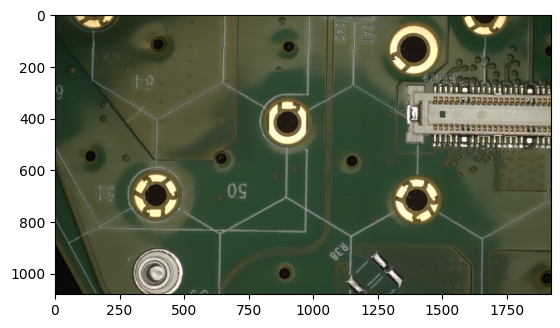

In [9]:
sample_segment = unaligned_images[5][3]
plt.imshow(sample_segment[..., ::-1])

In [2]:
def extract_board_id(path_or_name):
    match = BOARD_ID_RE.search(str(path_or_name))
    if not match:
        raise ValueError(f'Could not extract board ID from: {path_or_name}')

    return match.group(1)


def build_board_index():
    index = {}
    duplicates = {}

    for split, folder in BOARD_DIRS.items():
        if not folder.exists():
            continue

        for path in sorted(folder.iterdir()):
            if not path.is_file():
                continue

            board_id = extract_board_id(path.name)
            record = {
                'board_id': board_id,
                'split': split,
                'path': path,
                'filename': path.name,
            }

            if board_id in index:
                duplicates.setdefault(board_id, [index[board_id]['path']])
                duplicates[board_id].append(path)

            index[board_id] = record

    if duplicates:
        formatted = {
            board_id: [str(path) for path in paths]
            for board_id, paths in duplicates.items()
        }
        raise ValueError(f'Duplicate board IDs found: {formatted}')

    return dict(sorted(index.items()))


def summarize_index(index=None, preview=8):
    index = BOARD_INDEX if index is None else index
    split_counts = {split: 0 for split in BOARD_DIRS}
    for record in index.values():
        split_counts[record['split']] += 1

    print(f"Repo root: {PROJECT_DIR}")
    for split in ('train', 'val', 'test', 'bad'):
        print(f"{split.title()} boards: {split_counts[split]}")
    print(f"Total boards: {len(index)}")

    print()
    print('Sample board IDs:')
    for board_id in list(index)[:preview]:
        record = index[board_id]
        print(f"- {board_id} [{record['split']}] -> {record['filename']}")


def find_boards(query, index=None):
    index = BOARD_INDEX if index is None else index
    query = str(query)
    matches = [
        record for record in index.values()
        if query in record['board_id'] or query in record['filename']
    ]
    for record in matches:
        print(f"{record['board_id']} [{record['split']}] -> {record['path'].as_posix()}")

    return matches


def resolve_board_record(board_ref, index=None):
    index = BOARD_INDEX if index is None else index

    if isinstance(board_ref, dict):
        return board_ref

    if isinstance(board_ref, Path):
        path = board_ref
        if not path.exists():
            raise FileNotFoundError(path)

        board_id = extract_board_id(path.name)
        split = next(
            (split_name for split_name, folder in BOARD_DIRS.items() if path.parent == folder),
            'external',
        )
        return {
            'board_id': board_id,
            'split': split,
            'path': path,
            'filename': path.name,
        }

    board_ref = str(board_ref)
    if board_ref in index:
        return index[board_ref]

    direct_path = Path(board_ref)
    if direct_path.exists():
        return resolve_board_record(direct_path, index=index)

    matches = find_boards(board_ref, index=index)
    if len(matches) == 1:
        return matches[0]
    if not matches:
        raise KeyError(f'Board not found: {board_ref}')

    raise KeyError(f'Ambiguous board reference: {board_ref}')


def load_board(board_ref):
    record = resolve_board_record(board_ref)
    array = load_hexaboard(str(record['path']), normalize=False)
    return record, array


BOARD_INDEX = build_board_index()
summarize_index()

Repo root: /home/thanh/projects/visual-inspection
Train boards: 41
Val boards: 3
Test boards: 20
Bad boards: 59
Total boards: 123

Sample board IDs:
- 320XLF4CQH00001 [train] -> 320XLF4CQH00001.npy
- 320XLF4CQH00002 [train] -> 320XLF4CQH00002.npy
- 320XLF4CQH00004 [train] -> 320XLF4CQH00004.npy
- 320XLF4CQH00007 [train] -> 320XLF4CQH00007.npy
- 320XLF4CQH00008 [bad] -> 320XLF4CQH00008.npy
- 320XLF4CQH00010 [train] -> 320XLF4CQH00010.npy
- 320XLF4CQH00011 [train] -> 320XLF4CQH00011.npy
- 320XLF4CQH00012 [bad] -> 320XLF4CQH00012.npy


In [3]:
def orient_board(array, flip_rows=False, flip_cols=False):
    view = array
    if flip_rows:
        view = view[::-1, ...]
    if flip_cols:
        view = view[:, ::-1, ...]

    return view


def display_to_source_coords(row, col, rows, cols, flip_rows=False, flip_cols=False):
    source_row = rows - 1 - row if flip_rows else row
    source_col = cols - 1 - col if flip_cols else col
    return source_row, source_col


def to_grayscale(image):
    if image.ndim == 2:
        return image

    return np.dot(image[..., :3], np.array([0.299, 0.587, 0.114], dtype=np.float32))


def find_boards_with_reflective_segment(
    board_ref,
    location,
    *,
    threshold_scale=0.8,
    flip_rows=False,
    flip_cols=False,
    grayscale=False,
    show_segments=False,
    display_cols=4,
    max_display=None,
):
    reference_record, reference_board = load_board(board_ref)
    reference_view = orient_board(reference_board, flip_rows=flip_rows, flip_cols=flip_cols)
    row, col = location
    reference_segment = reference_view[row, col]
    if grayscale:
        reference_segment = to_grayscale(reference_segment)

    reference_std = float(np.std(reference_segment))
    threshold = threshold_scale * reference_std
    matching_board_ids = []
    matching_segment_stds = {}

    for candidate_board_id in BOARD_INDEX:
        _, board = load_board(candidate_board_id)
        board_view = orient_board(board, flip_rows=flip_rows, flip_cols=flip_cols)
        segment = board_view[row, col]
        if grayscale:
            segment = to_grayscale(segment)

        segment_std = float(np.std(segment))
        if segment_std > threshold:
            matching_board_ids.append(candidate_board_id)
            matching_segment_stds[candidate_board_id] = segment_std

    print(
        f"Reference board: {reference_record['board_id']} [{reference_record['split']}] | "
        f"segment r{row} c{col} | reference std={reference_std:.6f} | "
        f"threshold={threshold:.6f} | matches={len(matching_board_ids)}"
    )

    if show_segments and matching_board_ids:
        board_ids_to_display = matching_board_ids
        if max_display is not None:
            board_ids_to_display = board_ids_to_display[:max_display]

        display_cols = max(1, int(display_cols))
        display_rows = int(np.ceil(len(board_ids_to_display) / display_cols))
        fig, axes = plt.subplots(
            display_rows,
            display_cols,
            figsize=(display_cols * 4.0, display_rows * 3.0),
            dpi=150,
            squeeze=False,
        )

        for ax in axes.flat:
            ax.axis('off')

        for idx, candidate_board_id in enumerate(board_ids_to_display):
            record, board = load_board(candidate_board_id)
            board_view = orient_board(board, flip_rows=flip_rows, flip_cols=flip_cols)
            segment = board_view[row, col]
            if grayscale:
                image = to_grayscale(segment)
                axes.flat[idx].imshow(image, cmap='gray')
            else:
                axes.flat[idx].imshow(segment)

            axes.flat[idx].set_title(
                f"{record['board_id']} [{record['split']}]\nstd={matching_segment_stds[candidate_board_id]:.6f}",
                fontsize=9,
                pad=1.0,
            )
            axes.flat[idx].axis('off')

        fig.suptitle(
            f"Reflective segment matches for r{row} c{col} | "
            f"threshold={threshold:.6f} | displayed={len(board_ids_to_display)}",
            fontsize=12,
        )
        fig.tight_layout()
        display(fig)
        plt.close(fig)

    return matching_board_ids


def plot_board(
    board_ref,
    *,
    flip_rows=True,
    flip_cols=True,
    grayscale=False,
    annotate=True,
    figsize_per_segment=2.4,
    dpi=300,
):
    record, array = load_board(board_ref)
    rows, cols = array.shape[:2]

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(cols * figsize_per_segment, rows * figsize_per_segment * 0.75),
        dpi=dpi,
        squeeze=False,
    )

    for row in range(rows):
        for col in range(cols):
            source_row, source_col = display_to_source_coords(
                row,
                col,
                rows,
                cols,
                flip_rows=flip_rows,
                flip_cols=flip_cols,
            )
            image = array[source_row, source_col]
            ax = axes[row, col]
            if grayscale:
                ax.imshow(to_grayscale(image), cmap='gray')
            else:
                ax.imshow(image)

            if annotate:
                ax.set_title(f'r{source_row} c{source_col}', fontsize=8, pad=0.5)

            ax.axis('off')

    fig.suptitle(
        f"{record['board_id']} [{record['split']}]\n{record['filename']}\nshape={tuple(array.shape)}",
        fontsize=12,
    )
    fig.subplots_adjust(left=0.003, right=0.997, bottom=0.008, top=0.92, wspace=0.008, hspace=0.004)
    display(fig)
    plt.close(fig)
    return record, array


def plot_segment(
    board_ref,
    row,
    col,
    *,
    crop=None,
    flip_rows=False,
    flip_cols=False,
    grayscale=False,
    figsize=(8, 5),
    dpi=150,
):
    record, array = load_board(board_ref)
    board = orient_board(array, flip_rows=flip_rows, flip_cols=flip_cols)
    segment = board[row, col]

    if crop is not None:
        row_start, row_end, col_start, col_end = crop
        segment = segment[row_start:row_end, col_start:col_end]

    fig, ax = plt.subplots(figsize=figsize, dpi=dpi)
    if grayscale:
        ax.imshow(to_grayscale(segment), cmap='gray')
    else:
        ax.imshow(segment)

    ax.set_title(f"{record['board_id']} [{record['split']}] segment r{row} c{col}")
    ax.axis('off')
    fig.tight_layout()
    display(fig)
    plt.close(fig)
    return record, segment


In [4]:
def absolute_difference(image_a, image_b, grayscale=True):
    if grayscale:
        image_a = to_grayscale(image_a)
        image_b = to_grayscale(image_b)

    diff = np.abs(image_a.astype(np.int16) - image_b.astype(np.int16))
    return diff.astype(np.uint8)


def compare_boards(
    board_ref_a,
    board_ref_b,
    *,
    flip_rows=True,
    flip_cols=True,
    grayscale=True,
    figsize_per_segment=2.4,
    dpi=300,
):
    record_a, array_a = load_board(board_ref_a)
    record_b, array_b = load_board(board_ref_b)

    board_a = orient_board(array_a, flip_rows=flip_rows, flip_cols=flip_cols)
    board_b = orient_board(array_b, flip_rows=flip_rows, flip_cols=flip_cols)

    if board_a.shape != board_b.shape:
        raise ValueError(
            f'Shape mismatch: {record_a["board_id"]} {board_a.shape} vs ' 
            f'{record_b["board_id"]} {board_b.shape}'
        )

    rows, cols = board_a.shape[:2]
    scores = np.zeros((rows, cols), dtype=np.float32)

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(cols * figsize_per_segment, rows * figsize_per_segment * 0.75),
        dpi=dpi,
        squeeze=False,
    )

    for row in range(rows):
        for col in range(cols):
            diff = absolute_difference(board_a[row, col], board_b[row, col], grayscale=grayscale)
            scores[row, col] = float(diff.mean())
            source_row, source_col = display_to_source_coords(
                row,
                col,
                rows,
                cols,
                flip_rows=flip_rows,
                flip_cols=flip_cols,
            )
            ax = axes[row, col]
            ax.imshow(diff, cmap='gray', vmin=0, vmax=255)
            ax.set_title(f'r{source_row} c{source_col}\nmean={scores[row, col]:.1f}', fontsize=8, pad=0.5)
            ax.axis('off')

    fig.suptitle(
        f"Absolute difference: {record_a['board_id']} vs {record_b['board_id']}",
        fontsize=12,
    )
    fig.subplots_adjust(left=0.003, right=0.997, bottom=0.008, top=0.92, wspace=0.008, hspace=0.01)
    display(fig)
    plt.close(fig)

    heatmap_fig, heatmap_ax = plt.subplots(figsize=(rows, cols), dpi=dpi)
    sns.heatmap(
        scores,
        ax=heatmap_ax,
        cmap='magma',
        annot=True,
        fmt='.1f',
        cbar_kws={'label': 'Mean abs diff', 'shrink': 0.8},
        square=False,
    )
    heatmap_ax.set_title(
        f"Per-segment mean absolute difference\n{record_a['board_id']} vs {record_b['board_id']}"
    )
    heatmap_ax.set_xlabel('Column')
    heatmap_ax.set_ylabel('Row')
    heatmap_ax.set_xticklabels(range(cols))
    heatmap_ax.set_yticklabels(range(rows), rotation=0)
    heatmap_fig.tight_layout()
    display(heatmap_fig)
    plt.close(heatmap_fig)
    return scores

In [5]:
def launch_board_viewer(default_split='bad'):
    def board_ids_for_split(split):
        return [
            board_id
            for board_id, record in BOARD_INDEX.items()
            if record['split'] == split
        ]

    split_widget = widgets.Dropdown(
        options=['bad', 'train', 'val', 'test'],
        value=default_split,
        description='Split',
    )
    board_widget = widgets.Dropdown(
        options=(),
        description='Board ID',
        layout=widgets.Layout(width='420px'),
    )
    grayscale_widget = widgets.Checkbox(value=False, description='Grayscale')
    flip_rows_widget = widgets.Checkbox(value=True, description='Flip rows')
    flip_cols_widget = widgets.Checkbox(value=True, description='Flip cols')
    segment_labels_widget = widgets.Checkbox(value=True, description='Labels')
    output = widgets.Output()

    controls = widgets.HBox([
        split_widget,
        board_widget,
        grayscale_widget,
        flip_rows_widget,
        flip_cols_widget,
        segment_labels_widget,
    ])

    def render_board(change=None):
        board_id = board_widget.value
        output.clear_output(wait=True)

        with output:
            if not board_id:
                print('No boards available for this split.')
                return

            plot_board(
                board_id,
                grayscale=grayscale_widget.value,
                flip_rows=flip_rows_widget.value,
                flip_cols=flip_cols_widget.value,
                annotate=segment_labels_widget.value,
            )

    def handle_control_change(change):
        render_board()

    def sync_board_dropdown(preserve_current=True):
        options = board_ids_for_split(split_widget.value)
        current_value = board_widget.value
        next_value = None
        if options:
            if preserve_current and current_value in options:
                next_value = current_value
            else:
                next_value = options[0]

        board_widget.unobserve(handle_control_change, names='value')
        try:
            board_widget.options = options
            board_widget.value = next_value
        finally:
            board_widget.observe(handle_control_change, names='value')

    def handle_split_change(change):
        sync_board_dropdown(preserve_current=False)
        render_board()

    split_widget.observe(handle_split_change, names='value')
    for widget in (
        board_widget,
        grayscale_widget,
        flip_rows_widget,
        flip_cols_widget,
        segment_labels_widget,
    ):
        widget.observe(handle_control_change, names='value')

    sync_board_dropdown(preserve_current=False)
    render_board()
    return widgets.VBox([controls, output])

In [6]:
launch_board_viewer()

Reference board: 320XLF4CQH00422 [test] | segment r1 c1 | reference std=47.771365 | threshold=38.217092 | matches=123


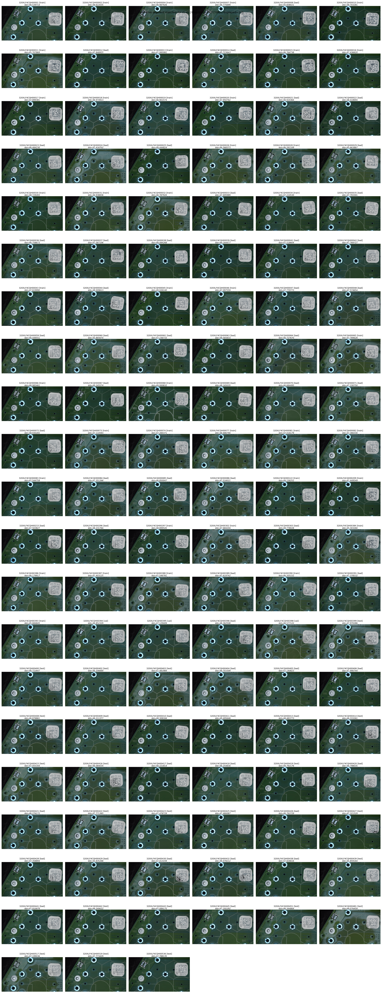

['320XLF4CQH00001',
 '320XLF4CQH00002',
 '320XLF4CQH00004',
 '320XLF4CQH00007',
 '320XLF4CQH00008',
 '320XLF4CQH00010',
 '320XLF4CQH00011',
 '320XLF4CQH00012',
 '320XLF4CQH00013',
 '320XLF4CQH00014',
 '320XLF4CQH00015',
 '320XLF4CQH00016',
 '320XLF4CQH00017',
 '320XLF4CQH00018',
 '320XLF4CQH00019',
 '320XLF4CQH00020',
 '320XLF4CQH00021',
 '320XLF4CQH00022',
 '320XLF4CQH00023',
 '320XLF4CQH00024',
 '320XLF4CQH00025',
 '320XLF4CQH00026',
 '320XLF4CQH00028',
 '320XLF4CQH00029',
 '320XLF4CQH00030',
 '320XLF4CQH00031',
 '320XLF4CQH00032',
 '320XLF4CQH00033',
 '320XLF4CQH00034',
 '320XLF4CQH00035',
 '320XLF4CQH00036',
 '320XLF4CQH00037',
 '320XLF4CQH00038',
 '320XLF4CQH00039',
 '320XLF4CQH00041',
 '320XLF4CQH00042',
 '320XLF4CQH00043',
 '320XLF4CQH00044',
 '320XLF4CQH00045',
 '320XLF4CQH00046',
 '320XLF4CQH00047',
 '320XLF4CQH00048',
 '320XLF4CQH00059',
 '320XLF4CQH00060',
 '320XLF4CQH00061',
 '320XLF4CQH00063',
 '320XLF4CQH00064',
 '320XLF4CQH00065',
 '320XLF4CQH00066',
 '320XLF4CQH00067',


In [8]:
# Inspect reflection across segments
find_boards_with_reflective_segment(
    board_ref=str(DATA_DIR / 'test' / '320XLF4CQH00422.npy'),
    location=(1, 1),
    threshold_scale=0.8,
    flip_rows=True,
    flip_cols=True,
    grayscale=False,
    show_segments=True,
    display_cols=6,
    max_display=123
)

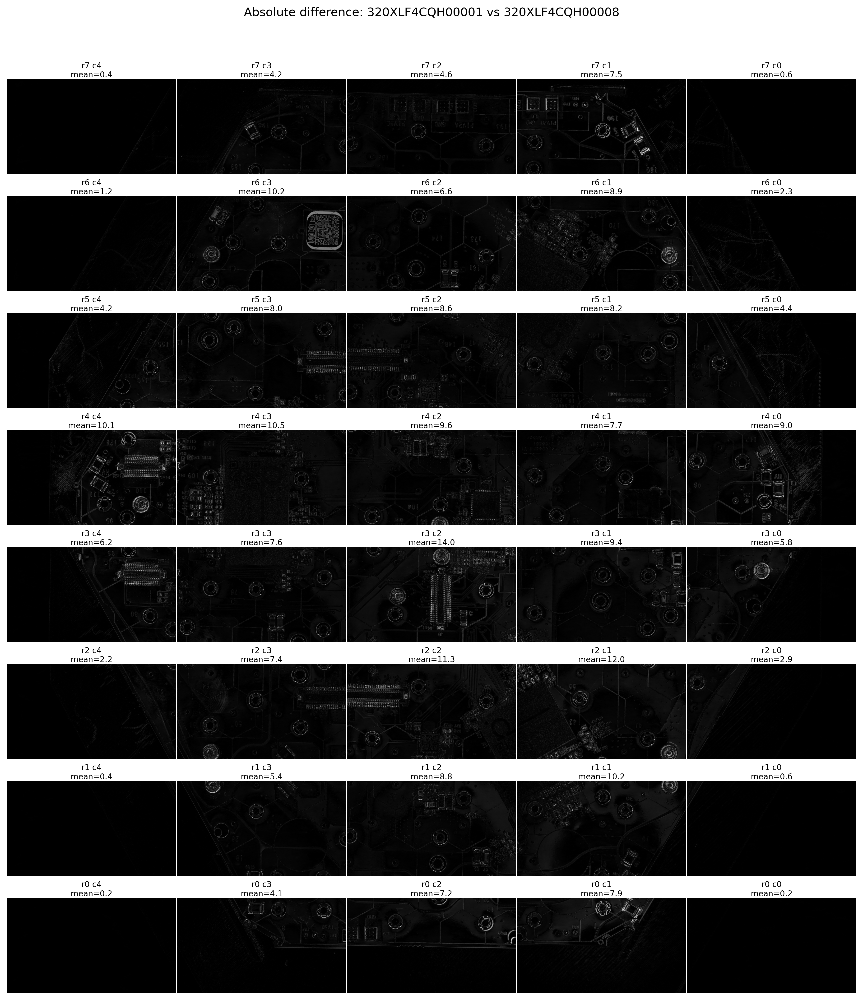

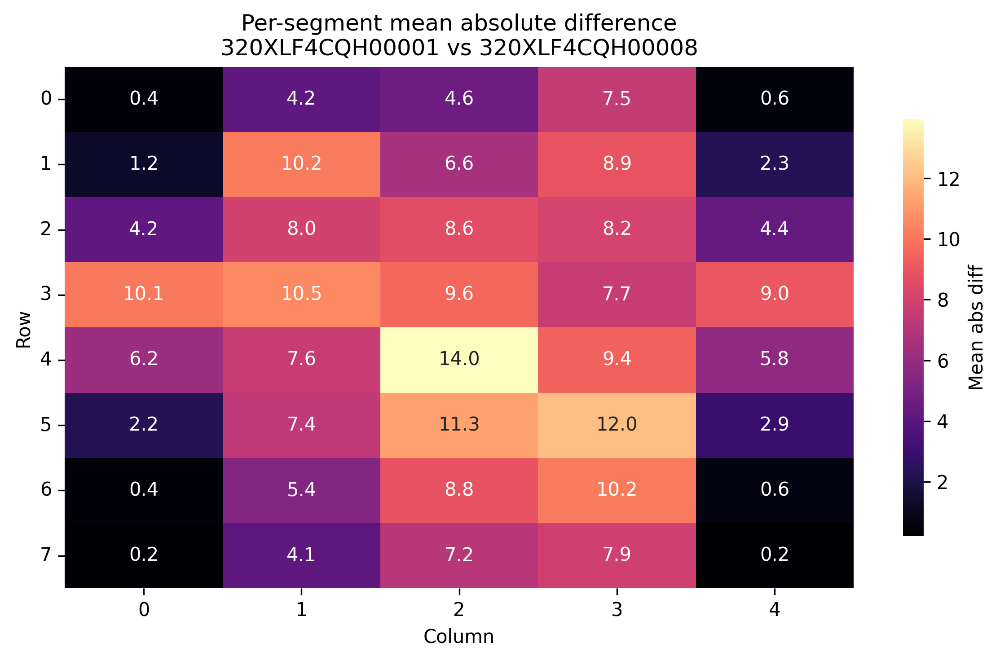

In [7]:
# Manual examples
diff_matrix = compare_boards('320XLF4CQH00001', '320XLF4CQH00008', grayscale=True)